## Graph Stracture using ** Pydantic ** ##

In [14]:
from langchain_openai import ChatOpenAI
from dotenv import load_dotenv
import os
load_dotenv()

if os.environ['OPENAI_API_KEY']:
    print("Openai key is set")
else:
    raise ValueError("openAi key is not set")


llm_openai = ChatOpenAI(model='gpt-5-mini',temperature=0)



Openai key is set


In [15]:
from pydantic import BaseModel, Field

class graph_schema (BaseModel):
    topic : str = Field(description= "This is topic")
    post : str =Field(description= "Linkedin Post context")
    curected_post : str = Field(description="this is curected post for linkdein")




In [16]:
obj = graph_schema(
    topic="Create A Linkdein Post ",
    post="Demo",
    curected_post="Curected post"
)
obj.model_dump()

{'topic': 'Create A Linkdein Post ',
 'post': 'Demo',
 'curected_post': 'Curected post'}

Create Nodes

In [17]:

##Create post
def create_post (schema:graph_schema)-> graph_schema:
    schema = schema.model_dump()
    topic = schema['topic']
    ai_response = llm_openai.invoke(f" Write a linkedin post about {topic}").content
    schema['post'] = ai_response
    return schema


## Currect post
def currect_post (schema:graph_schema) -> graph_schema:
    schema = schema.model_dump()
    topic= schema['post']
    ai_response = llm_openai.invoke(f"Cirrect the follwing post for linkedin {topic}").content
    schema['curected_post']=ai_response
    return schema



## Connect the State Graph ##

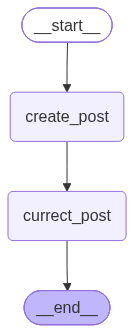

In [18]:
from langgraph.graph import StateGraph, START,END

graph= StateGraph(graph_schema)

## Connect the node
graph.add_node('create_post',create_post)
graph.add_node('currect_post',currect_post)

## Connect the edge
graph.add_edge(START,"create_post")
graph.add_edge('create_post','currect_post')
graph.add_edge('currect_post',END)

final_graph=graph.compile()

from IPython.display import Image,display

Image(final_graph.get_graph().draw_mermaid_png())



In [19]:
final_graph.invoke({"topic" :"Ai as a Software devloper","post":"","curected_post":""})

{'topic': 'Ai as a Software devloper',
 'post': 'As a software developer, the rise of AI is less about replacing us and more about amplifying what we do best: solving hard problems, designing systems, and delivering value.\n\nAI tools are now part of my daily workflow — from generating boilerplate, suggesting tests, and catching security issues, to helping sketch architecture options and speeding up prototyping. They cut repetitive work and let me focus more on higher-level design, product thinking, and user experience.\n\nThat said, AI is a tool, not an oracle. Outputs still need critical review: correctness, security, maintainability, and alignment with product requirements. The best results come from pairing domain expertise with AI assistance — prompt well, verify thoroughly, and iterate.\n\nAs developers we also have new responsibilities: choosing the right data and models, preventing bias, designing for explainability, and building robust CI/CD/ML-Ops practices. Upskilling matter